# PS1 — MNIST Handwritten Digit Classification (CNN)


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
BATCH_SIZE = 128
EPOCHS = 15
SAVE_TO_DRIVE = False

keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


In [ ]:
gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
if gpus:
    print('GPU detected:', gpus[0].name)
    try:
        import pynvml
        pynvml.nvmlInit()
        info = pynvml.nvmlDeviceGetMemoryInfo(pynvml.nvmlDeviceGetHandleByIndex(0))
        print(f'VRAM: {info.total / 1024**3:.1f} GB total, {info.free / 1024**3:.1f} GB free')
    except Exception:
        pass
else:
    print('No GPU found. PS1 is light, so a CPU runtime also works (just slower).')

GPU detected: /physical_device:GPU:0
VRAM: 15.0 GB total, 14.6 GB free


In [ ]:
OUT_DIR = 'outputs'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/ps01_mnist'
os.makedirs(OUT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(OUT_DIR, 'best_model.keras')
print('Saving artifacts to:', OUT_DIR)

Saving artifacts to: outputs


## Data


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28, 1) Test: (10000, 28, 28, 1)


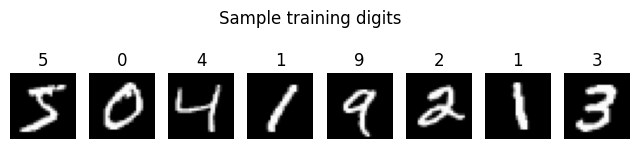

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.astype('float32')[..., None] / 255.0
x_test = x_test.astype('float32')[..., None] / 255.0
print('Train:', x_train.shape, 'Test:', x_test.shape)

plt.figure(figsize=(8, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title(str(y_train[i]))
    plt.axis('off')
plt.suptitle('Sample training digits')
plt.show()

## Model


In [ ]:
model = keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Training


In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT_PATH, monitor='val_accuracy', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
]
history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/15
422/422 - 20s - 47ms/step - accuracy: 0.9297 - loss: 0.2372 - val_accuracy: 0.9817 - val_loss: 0.0642 - learning_rate: 0.0010
Epoch 2/15
422/422 - 2s - 5ms/step - accuracy: 0.9785 - loss: 0.0695 - val_accuracy: 0.9885 - val_loss: 0.0423 - learning_rate: 0.0010
Epoch 3/15
422/422 - 2s - 4ms/step - accuracy: 0.9847 - loss: 0.0502 - val_accuracy: 0.9890 - val_loss: 0.0373 - learning_rate: 0.0010
Epoch 4/15
422/422 - 2s - 4ms/step - accuracy: 0.9870 - loss: 0.0404 - val_accuracy: 0.9902 - val_loss: 0.0343 - learning_rate: 0.0010
Epoch 5/15
422/422 - 2s - 4ms/step - accuracy: 0.9894 - loss: 0.0326 - val_accuracy: 0.9902 - val_loss: 0.0369 - learning_rate: 0.0010
Epoch 6/15
422/422 - 2s - 6ms/step - accuracy: 0.9912 - loss: 0.0279 - val_accuracy: 0.9908 - val_loss: 0.0328 - learning_rate: 0.0010
Epoch 7/15
422/422 - 2s - 6ms/step - accuracy: 0.9922 - loss: 0.0241 - val_accuracy: 0.9918 - val_loss: 0.0312 - learning_rate: 0.0010
Epoch 8/15
422/422 - 2s - 4ms/step - accuracy: 0.9922

## Evaluation


Test accuracy: 0.9937   Test loss: 0.0224


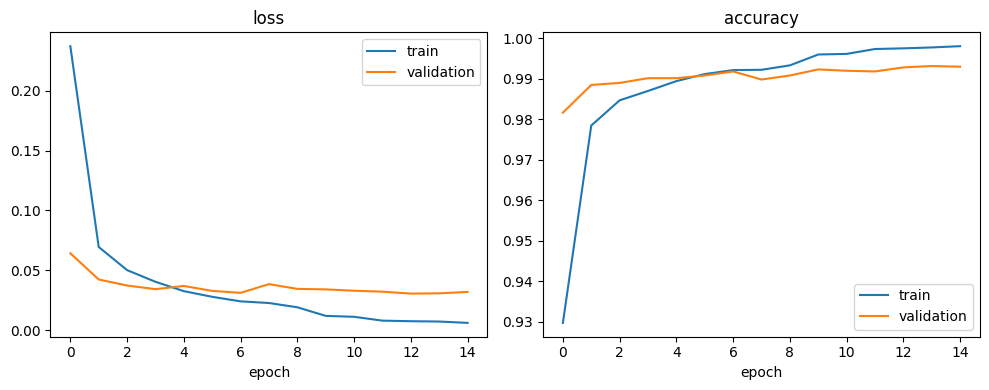

In [ ]:
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Test accuracy: {acc:.4f}   Test loss: {loss:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(['loss', 'accuracy']):
    ax[i].plot(history.history[metric], label='train')
    ax[i].plot(history.history['val_' + metric], label='validation')
    ax[i].set_title(metric)
    ax[i].set_xlabel('epoch')
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0     0.9959    0.9959    0.9959       980
           1     0.9947    0.9982    0.9965      1135
           2     0.9875    0.9961    0.9918      1032
           3     0.9950    0.9921    0.9936      1010
           4     0.9929    0.9969    0.9949       982
           5     0.9899    0.9933    0.9916       892
           6     0.9969    0.9927    0.9948       958
           7     0.9951    0.9903    0.9927      1028
           8     0.9928    0.9938    0.9933       974
           9     0.9960    0.9871    0.9915      1009

    accuracy                         0.9937     10000
   macro avg     0.9937    0.9936    0.9937     10000
weighted avg     0.9937    0.9937    0.9937     10000



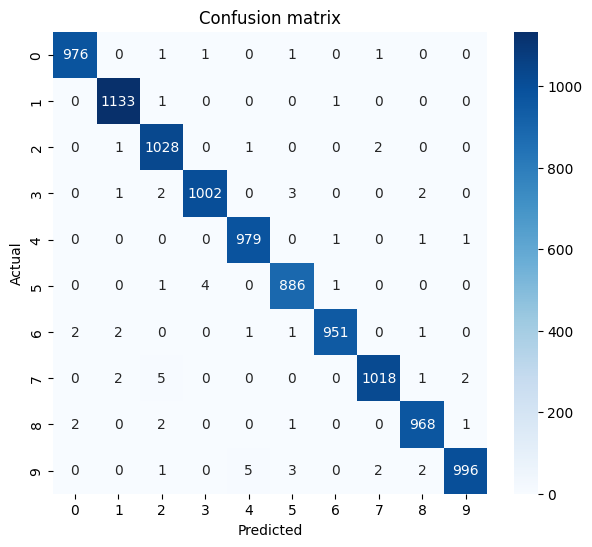

In [ ]:
y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

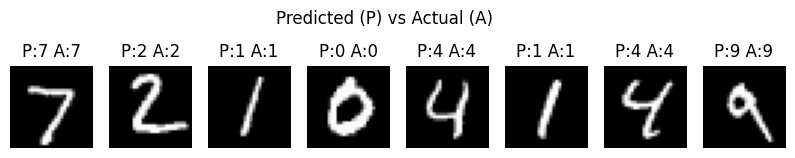

In [ ]:
plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title(f'P:{y_pred[i]} A:{y_test[i]}')
    plt.axis('off')
plt.suptitle('Predicted (P) vs Actual (A)')
plt.show()

## Single-image demo & save


Actual: 7   Predicted: 7   Confidence: 1.000


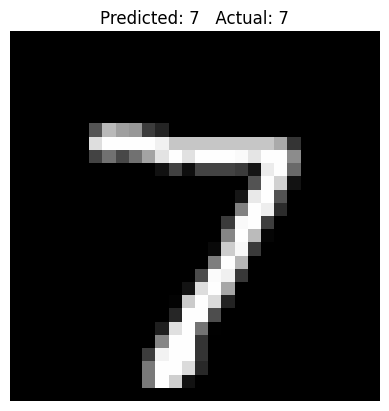

In [ ]:
image_index = 0
test_image = x_test[image_index]
true_label = int(y_test[image_index])
probs = model.predict(np.expand_dims(test_image, 0), verbose=0)[0]
predicted_label = int(probs.argmax())
print(f'Actual: {true_label}   Predicted: {predicted_label}   Confidence: {probs[predicted_label]:.3f}')
plt.imshow(test_image.squeeze(), cmap='gray')
plt.title(f'Predicted: {predicted_label}   Actual: {true_label}')
plt.axis('off')
plt.show()

In [ ]:
final_path = os.path.join(OUT_DIR, 'final_model.keras')
model.save(final_path)
pd.DataFrame(history.history).to_csv(os.path.join(OUT_DIR, 'training_log.csv'), index=False)
print('Saved best checkpoint:', CKPT_PATH)
print('Saved final model:', final_path)

Saved best checkpoint: outputs/best_model.keras
Saved final model: outputs/final_model.keras
